In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Professional visualization settings
sns.set_theme(style="whitegrid", palette="deep")

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300

# Create folder for saving charts
CHART_DIR = Path("charts")
CHART_DIR.mkdir(parents=True, exist_ok=True)

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
# Load the retail dataset
df = pd.read_csv("Downloads/retail.csv")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Number of rows: 541909
Number of columns: 8


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


In [5]:
# Work on a copy of the original dataset
df = df.copy()

# Convert data types
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"], errors="coerce"
)

df["Quantity"] = pd.to_numeric(
    df["Quantity"], errors="coerce"
)

df["UnitPrice"] = pd.to_numeric(
    df["UnitPrice"], errors="coerce"
)

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Remove records with missing essential values
df = df.dropna(
    subset=["InvoiceDate", "Quantity", "UnitPrice", "Country"]
).copy()

# Calculate transaction value
df["Sales"] = df["Quantity"] * df["UnitPrice"]

# Create month column
df["Month"] = df["InvoiceDate"].dt.to_period("M").dt.to_timestamp()

# Separate ordinary sales from cancellations and returns
df["InvoiceNo"] = df["InvoiceNo"].astype(str)

sales_df = df[
    (~df["InvoiceNo"].str.startswith("C")) &
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

print("Original dataset shape:", df.shape)
print("Valid positive-sale records:", sales_df.shape[0])

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDescriptive statistics:")
display(sales_df[["Quantity", "UnitPrice", "Sales"]].describe())

Original dataset shape: (536641, 10)
Valid positive-sale records: 524878

Missing values:


,Missing Values
InvoiceNo,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,0
Country,0
Sales,0
Month,0



Descriptive statistics:


,Quantity,UnitPrice,Sales
count,524878.000000,524878.000000,524878.000000
mean,10.616600,3.922573,20.275399
std,156.280031,36.093028,271.693566
min,1.000000,0.001000,0.001000
25%,1.000000,1.250000,3.900000
50%,4.000000,2.080000,9.920000
75%,11.000000,4.130000,17.700000
max,80995.000000,13541.330000,168469.600000


## Chart 1 — Line chart: Monthly sales trend

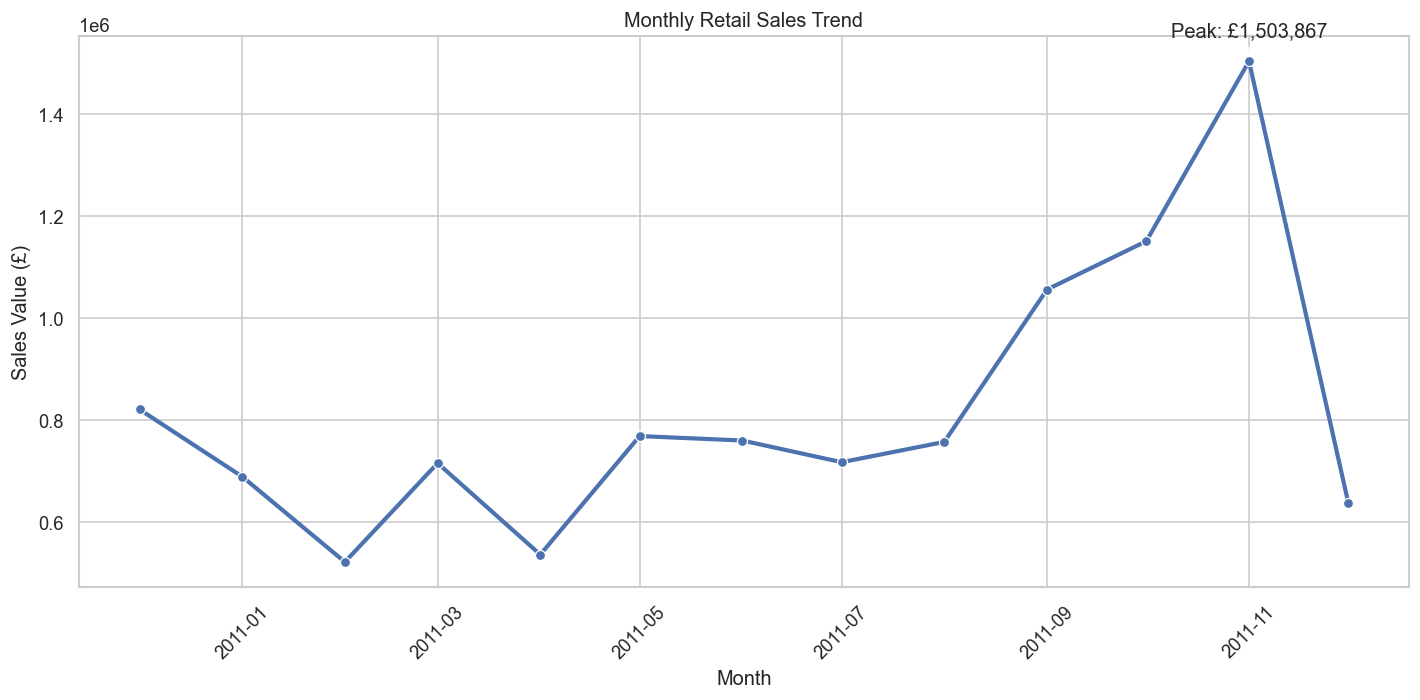

In [6]:
monthly_sales = (
    sales_df.groupby("Month", as_index=False)["Sales"]
    .sum()
    .sort_values("Month")
)

fig, ax = plt.subplots(figsize=(12, 6))

sns.lineplot(
    data=monthly_sales,
    x="Month",
    y="Sales",
    marker="o",
    linewidth=2.5,
    ax=ax
)

peak = monthly_sales.loc[monthly_sales["Sales"].idxmax()]

ax.annotate(
    f"Peak: £{peak['Sales']:,.0f}",
    xy=(peak["Month"], peak["Sales"]),
    xytext=(0, 15),
    textcoords="offset points",
    ha="center",
    arrowprops={"arrowstyle": "->"}
)

ax.set_title("Monthly Retail Sales Trend")
ax.set_xlabel("Month")
ax.set_ylabel("Sales Value (£)")

plt.xticks(rotation=45)
plt.tight_layout()

fig.savefig(CHART_DIR / "line_chart.png", bbox_inches="tight")
plt.show()

# Insight: Identifies months with the highest and lowest sales values.

## Chart 2 — Bar chart: Top 10 countries by sales

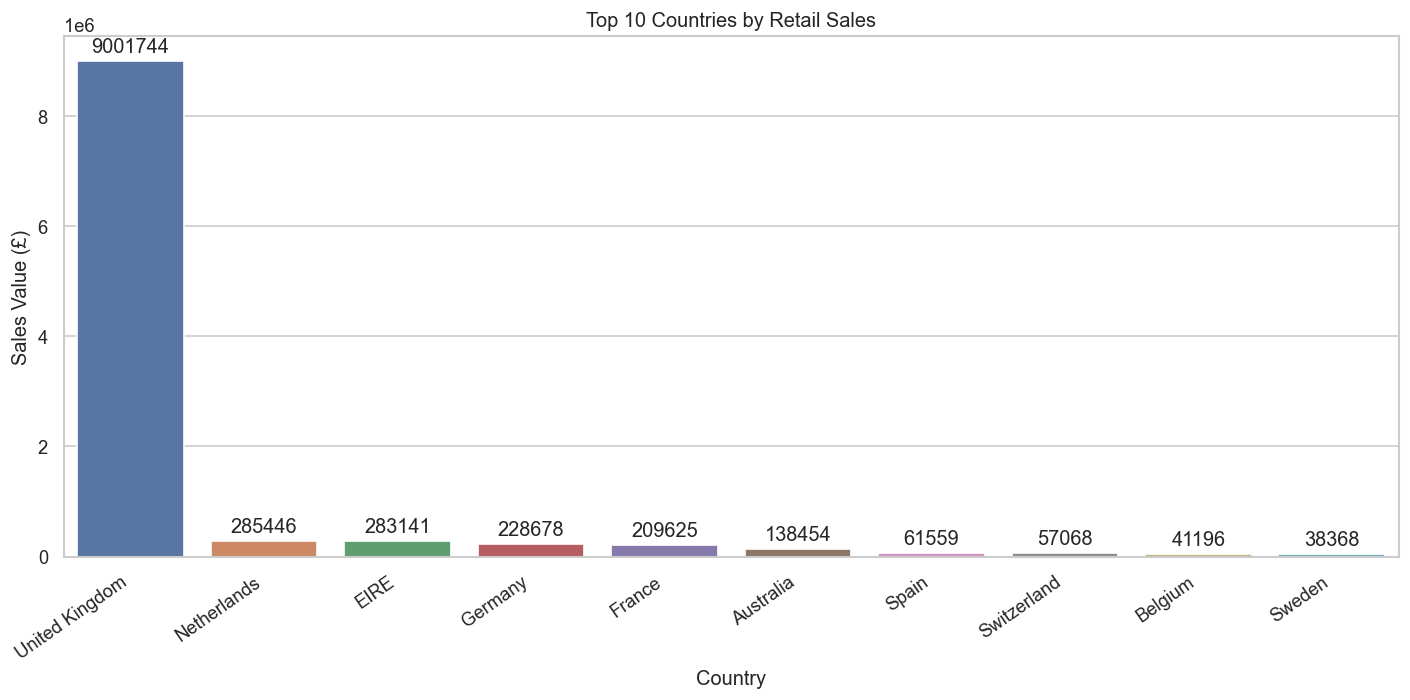

In [7]:
country_sales = (
    sales_df.groupby("Country", as_index=False)["Sales"]
    .sum()
    .sort_values("Sales", ascending=False)
    .head(10)
)

fig, ax = plt.subplots(figsize=(12, 6))

sns.barplot(
    data=country_sales,
    x="Country",
    y="Sales",
    hue="Country",
    legend=False,
    ax=ax
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

ax.set_title("Top 10 Countries by Retail Sales")
ax.set_xlabel("Country")
ax.set_ylabel("Sales Value (£)")

plt.xticks(rotation=35, ha="right")
plt.tight_layout()

fig.savefig(CHART_DIR / "bar_chart.png", bbox_inches="tight")
plt.show()

# Insight: Compares sales values across the leading countries.

## Chart 3 — Scatter plot: Quantity versus sales value

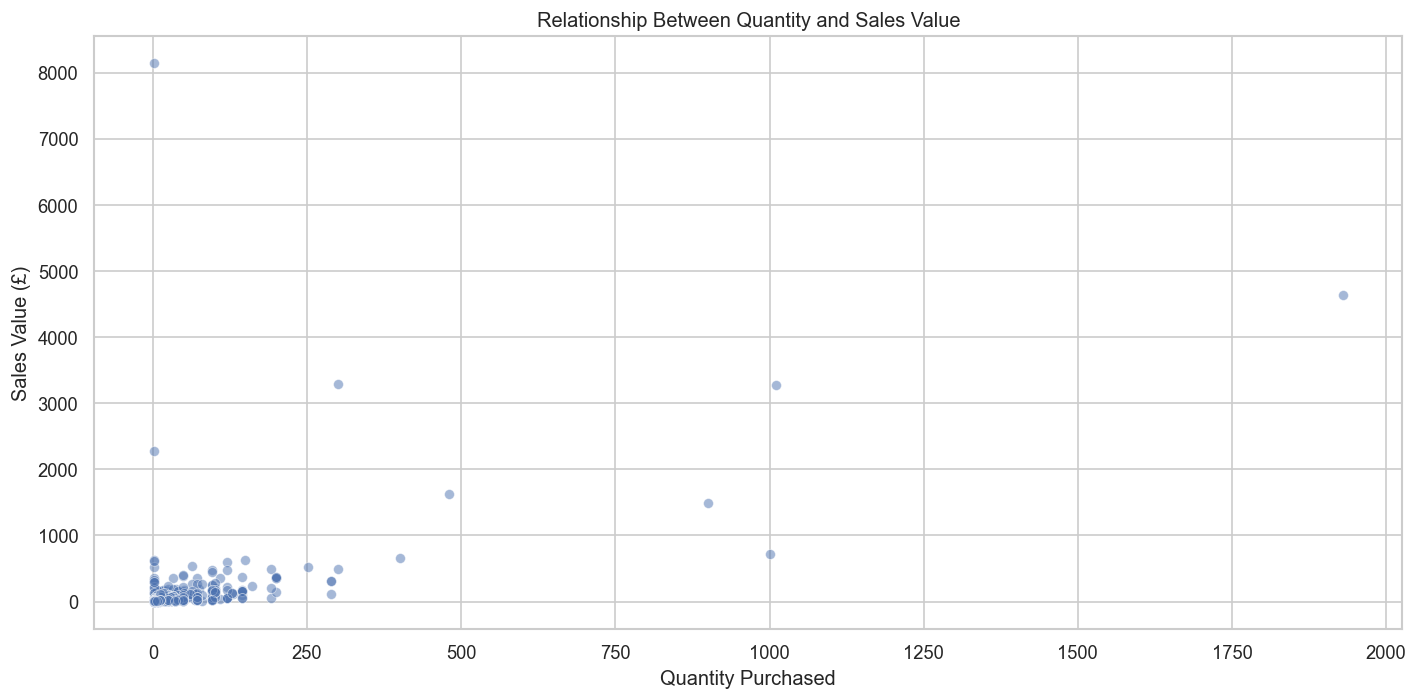

Quantity-sales correlation: 0.552


In [8]:
# Sample records for readability and faster plotting
scatter_data = sales_df.sample(
    n=min(5000, len(sales_df)),
    random_state=42
)

fig, ax = plt.subplots(figsize=(12, 6))

sns.scatterplot(
    data=scatter_data,
    x="Quantity",
    y="Sales",
    alpha=0.5,
    s=35,
    ax=ax
)

ax.set_title("Relationship Between Quantity and Sales Value")
ax.set_xlabel("Quantity Purchased")
ax.set_ylabel("Sales Value (£)")

plt.tight_layout()

fig.savefig(CHART_DIR / "scatter_plot.png", bbox_inches="tight")
plt.show()

correlation = scatter_data["Quantity"].corr(scatter_data["Sales"])

print("Quantity-sales correlation:", round(correlation, 3))

# Insight: Examines how quantities purchased relate to transaction values.

## Chart 4 — Histogram: Distribution of transaction values

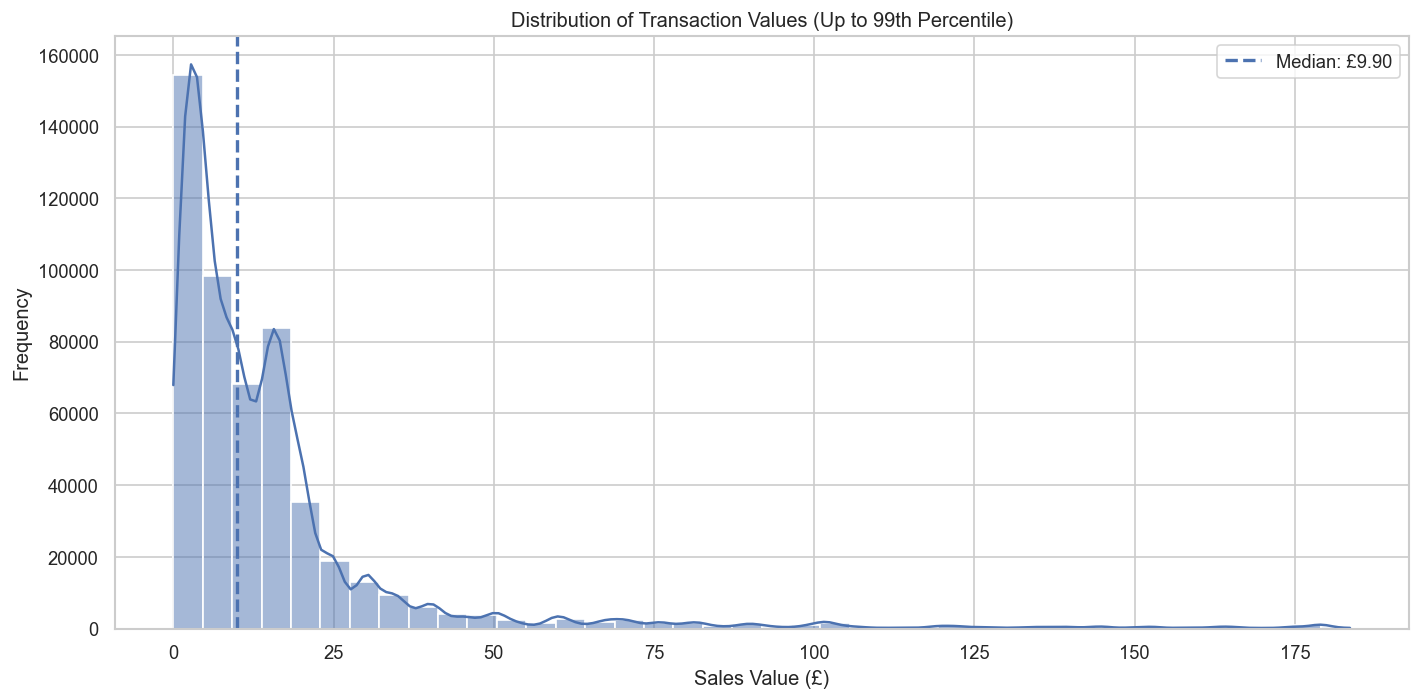

In [9]:
# Restrict the display range to the 99th percentile
# to make the central distribution easier to inspect.
sales_limit = sales_df["Sales"].quantile(0.99)

hist_data = sales_df.loc[
    sales_df["Sales"] <= sales_limit
].copy()

fig, ax = plt.subplots(figsize=(12, 6))

sns.histplot(
    data=hist_data,
    x="Sales",
    bins=40,
    kde=True,
    ax=ax
)

median_sales = hist_data["Sales"].median()

ax.axvline(
    median_sales,
    linestyle="--",
    linewidth=2,
    label=f"Median: £{median_sales:.2f}"
)

ax.set_title("Distribution of Transaction Values (Up to 99th Percentile)")
ax.set_xlabel("Sales Value (£)")
ax.set_ylabel("Frequency")
ax.legend()

plt.tight_layout()

fig.savefig(CHART_DIR / "histogram.png", bbox_inches="tight")
plt.show()

# Insight: Shows the distribution of transaction values without allowing a few very large transactions to dominate the display.

## Chart 5 — Box plot: Transaction values by country

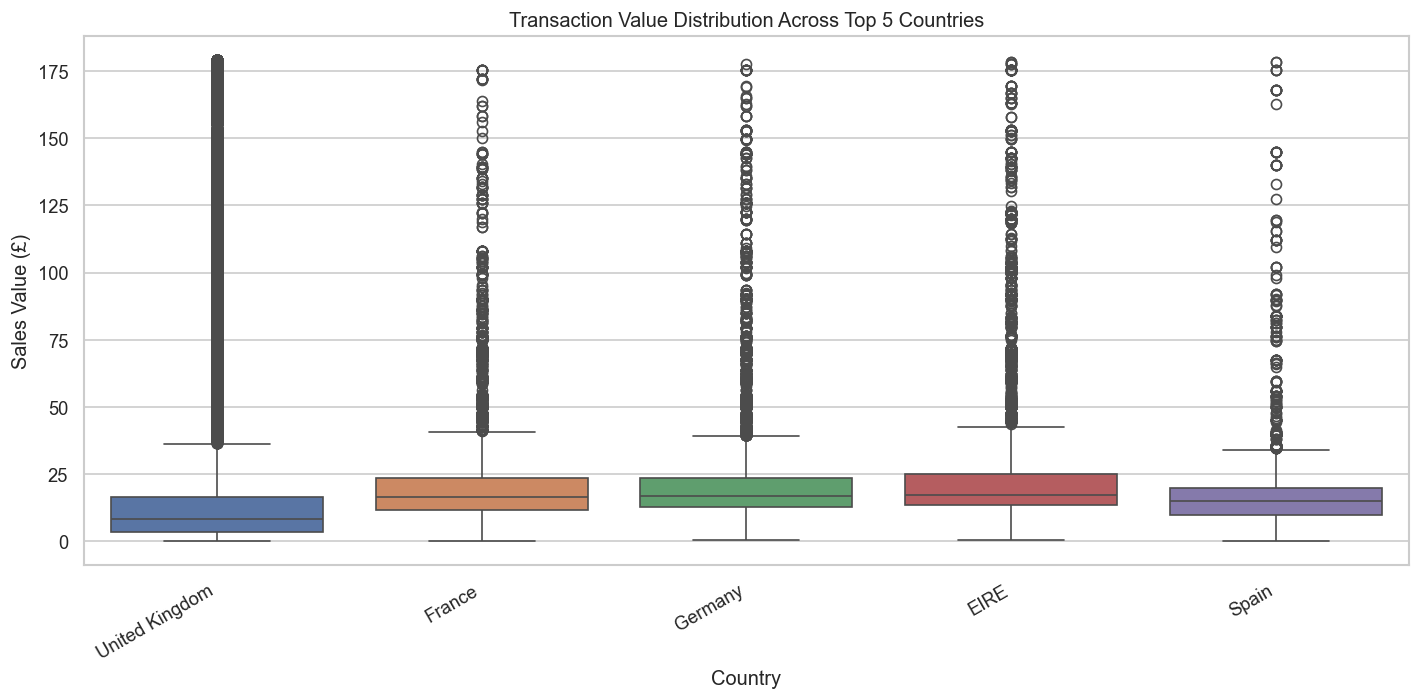

In [10]:
# Select the top five countries by transaction count
top_countries = (
    sales_df["Country"]
    .value_counts()
    .head(5)
    .index
)

box_data = sales_df[
    sales_df["Country"].isin(top_countries)
].copy()

# Restrict the display to the 99th percentile
box_limit = box_data["Sales"].quantile(0.99)

box_data = box_data[
    box_data["Sales"] <= box_limit
]

fig, ax = plt.subplots(figsize=(12, 6))

sns.boxplot(
    data=box_data,
    x="Country",
    y="Sales",
    hue="Country",
    legend=False,
    ax=ax
)

ax.set_title("Transaction Value Distribution Across Top 5 Countries")
ax.set_xlabel("Country")
ax.set_ylabel("Sales Value (£)")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()

fig.savefig(CHART_DIR / "box_plot.png", bbox_inches="tight")
plt.show()

# Insight: Compares the median, spread, and potential outliers of transaction values across countries with the most transactions.

In [11]:
expected_files = [
    "line_chart.png",
    "bar_chart.png",
    "scatter_plot.png",
    "histogram.png",
    "box_plot.png"
]

for filename in expected_files:
    path = CHART_DIR / filename
    print(
        f"{filename}: {'SAVED' if path.exists() else 'MISSING'}"
    )

line_chart.png: SAVED
bar_chart.png: SAVED
scatter_plot.png: SAVED
histogram.png: SAVED
box_plot.png: SAVED
